# Zelle 1: Imports & Style Setup

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Styling-Settings für übersichtliche Plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Zelle 2: Datensatz laden & Grundstruktur prüfen

In [18]:
# Daten aus dem data-Ordner laden
df = pd.read_csv('data/traveltide_user_aggregates_demographics.csv')

print(f"Anzahl Nutzer (Zeilen): {df.shape[0]:,}")
print(f"Anzahl Merkmale (Spalten): {df.shape[1]}")
print("-" * 50)
df.info()

Anzahl Nutzer (Zeilen): 50,000
Anzahl Merkmale (Spalten): 31
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 31 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   user_id                          50000 non-null  int64  
 1   birthdate                        50000 non-null  str    
 2   age                              50000 non-null  int64  
 3   gender                           50000 non-null  str    
 4   married                          50000 non-null  bool   
 5   has_children                     50000 non-null  bool   
 6   home_airport                     50000 non-null  str    
 7   home_country                     50000 non-null  str    
 8   home_airport_lat                 50000 non-null  float64
 9   home_airport_lon                 50000 non-null  float64
 10  total_sessions                   50000 no

# Zelle 3: Umgang mit Null-Werten (Missing Values)
Hintergrund: Da manche User zwar Flüge, aber keine Hotels gebucht haben (oder umgekehrt), entstehen in Aggregatspalten wie avg_hotel_nights oder avg_checked_bags_per_flight natürlicherweise NaN-Werte. Diese füllen wir sachlogisch mit 0.

In [19]:
# 1. Übersicht über fehlende Werte
missing_summary = df.isnull().sum()[df.isnull().sum() > 0]
print("Fehlende Werte pro Spalte:\n", missing_summary)

# 2. Imputation: Wo keine Buchung vorlag, ist die Anzahl/Ausgabe = 0
fill_zero_cols = [
    'total_flights_booked', 'total_seats_booked', 'total_checked_bags', 
    'avg_checked_bags_per_flight', 'total_flight_spend_usd', 'avg_flight_price_usd',
    'total_hotels_booked', 'total_hotel_nights', 'avg_hotel_nights', 
    'total_hotel_spend_usd', 'avg_room_price_per_night_usd',
    'avg_flight_discount_pct', 'avg_hotel_discount_pct', 'cancellation_rate_pct',
    'combined_flight_and_hotel_trips'
]

# Vorhandene Spalten mit 0 auffüllen
for col in fill_zero_cols:
    if col in df.columns:
        df[col] = df[col].fillna(0)

print("\nNull-Werte erfolgreich behandelt!")

Fehlende Werte pro Spalte:
 avg_flight_discount_pct         23017
avg_hotel_discount_pct          27503
cancellation_rate_pct              75
total_seats_booked               4477
total_checked_bags               4477
avg_checked_bags_per_flight      4477
total_flight_spend_usd           4477
avg_flight_price_usd             4477
total_hotel_nights               4653
avg_hotel_nights                 4653
total_hotel_spend_usd            4653
avg_room_price_per_night_usd     4653
dtype: int64

Null-Werte erfolgreich behandelt!


# Zelle 4: Erster statistischer Überblick (df.describe())

In [20]:
# Numerische Spalten analysieren
df.describe().T[['mean', 'std', 'min', '50%', 'max']]

,mean,std,min,50%,max
user_id,253687.548140,95129.644494,55.000,273557.000,381850.000
age,44.062680,11.424838,19.000,44.000,93.000
home_airport_lat,38.514546,6.108692,21.316,39.175,61.251
home_airport_lon,-94.040376,18.115368,-157.927,-89.977,-63.499
total_sessions,4.414280,0.697267,2.000,4.000,9.000
avg_page_clicks,20.064815,12.433683,2.670,17.000,166.250
flight_discount_sessions,0.814840,0.822733,0.000,1.000,5.000
hotel_discount_sessions,0.657900,0.751531,0.000,1.000,5.000
avg_flight_discount_pct,0.075879,0.091008,0.000,0.050,0.850
avg_hotel_discount_pct,0.049836,0.067447,0.000,0.000,0.500


# Zelle 5 Ausreißer-Analyse & Verteilung

In [21]:
# Ausgewählte Kernmerkmale mit auffälligen Extremwerten untersuchen
outlier_cols = [
    'avg_page_clicks', 
    'cancellation_rate_pct', 
    'total_flight_spend_usd', 
    'avg_flight_price_usd', 
    'avg_room_price_per_night_usd', 
    'combined_flight_and_hotel_trips'
]

# Filter nur auf Spalten, die tatsächlich im Dataframe existieren
available_cols = [col for col in outlier_cols if col in df.columns]

# Perzentil-Übersicht (05%, 50%, 95%, 99% und Max)
print("Perzentil-Analyse der Kernmetriken:")
df[available_cols].quantile([0.05, 0.50, 0.95, 0.99, 1.00]).T

Perzentil-Analyse der Kernmetriken:


,0.05,0.50,0.95,0.99,1.00
avg_page_clicks,9.17,17.000,48.2520,70.7500,166.25
cancellation_rate_pct,0.00,0.000,50.0000,100.0000,100.00
total_flight_spend_usd,0.00,646.605,3696.2420,9680.7114,47788.47
avg_flight_price_usd,0.00,374.810,1866.9845,4922.6553,23168.72
avg_room_price_per_night_usd,0.00,148.000,347.0000,508.0100,1572.00
combined_flight_and_hotel_trips,0.00,1.000,3.0000,4.0000,6.00


# Zelle 6
## Verteilung Visualisieren per Boxplots

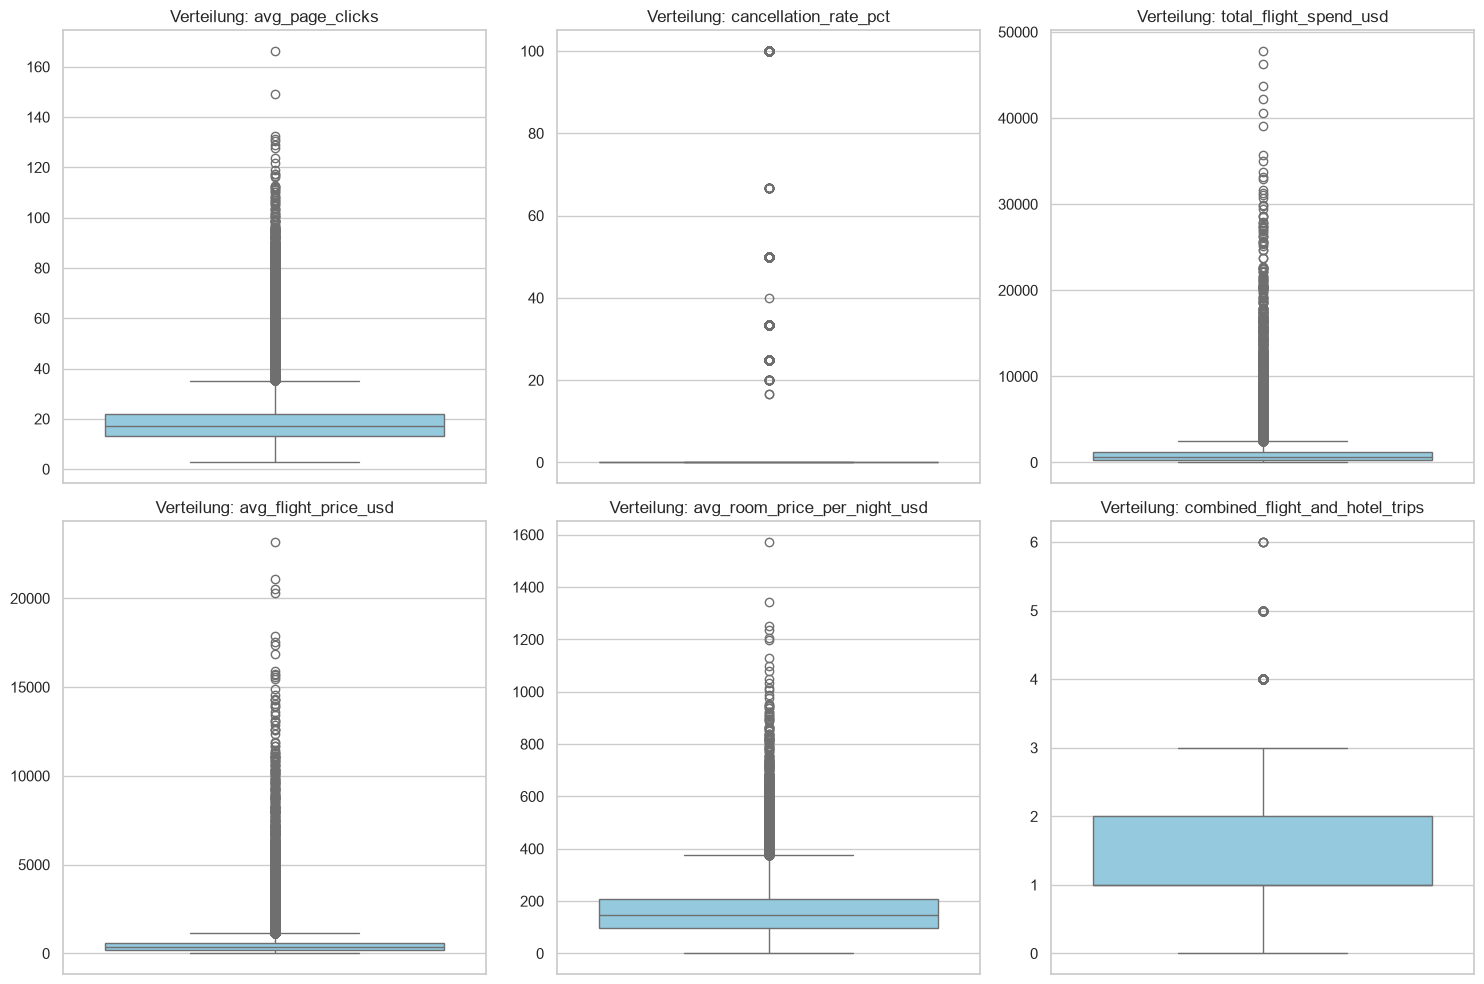

In [22]:
# Boxplots zur visuellen Identifikation von Ausreißern
plt.figure(figsize=(15, 10))

for i, col in enumerate(available_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Verteilung: {col}')
    plt.ylabel('')

plt.tight_layout()
plt.show()

# Zelle 8
1. Perzentil Ranking für die normierte Skalierung

Damit wird die Auswirkung von AUssreißern und Extremwerten vermindert

2. Cappung am 99%-Quantil

Damit werden Extremwerte sozusagen gedeckelt

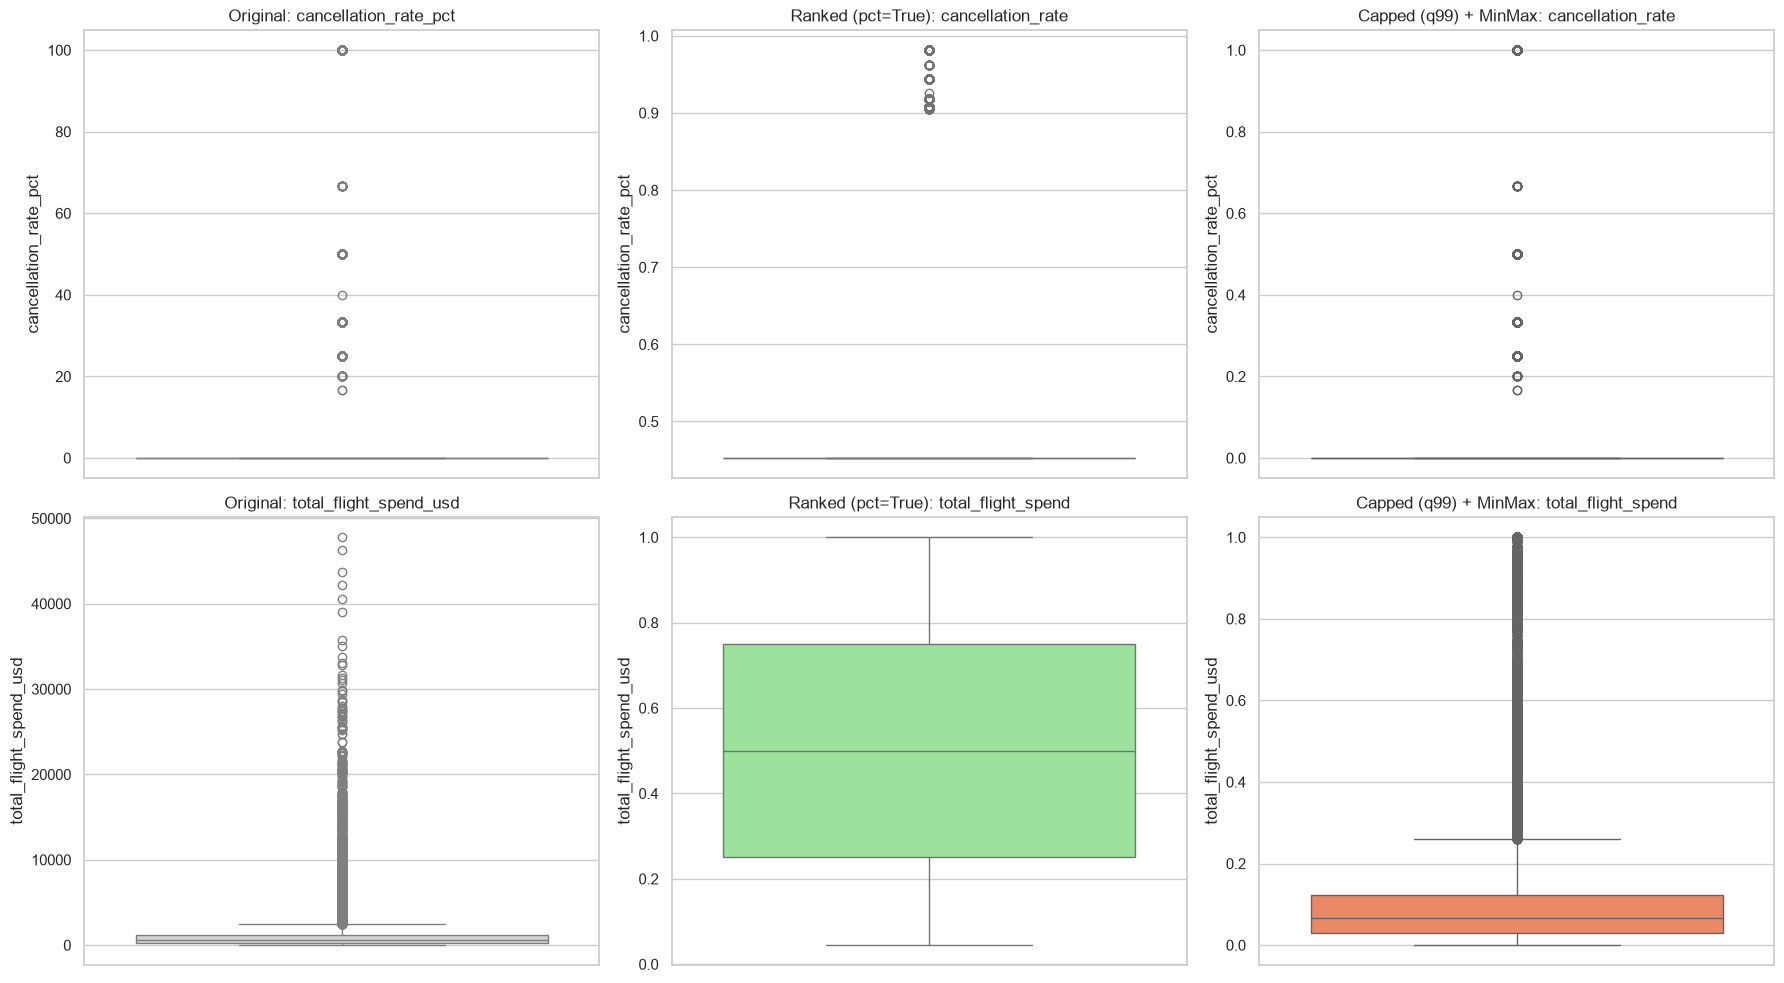

In [23]:
# 1. Perzentil-Ranking anwenden
df_ranked = df[available_cols].rank(pct=True)

# 2. Capping (am 99%-Quantil) + MinMax-Skalierung anwenden
df_capped = df[available_cols].copy()
for col in available_cols:
    q99 = df_capped[col].quantile(0.99)
    df_capped[col] = np.minimum(df_capped[col], q99)
    # MinMax-Skalierung auf [0, 1]
    col_min = df_capped[col].min()
    col_max = df_capped[col].max()
    if col_max > col_min:
        df_capped[col] = (df_capped[col] - col_min) / (col_max - col_min)

# Visualisierung des Vergleichs für cancellation_rate_pct und total_flight_spend_usd
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# cancellation_rate_pct: Original vs. Ranked vs. Capped
sns.boxplot(y=df['cancellation_rate_pct'], ax=axes[0, 0], color='lightgray').set_title('Original: cancellation_rate_pct')
sns.boxplot(y=df_ranked['cancellation_rate_pct'], ax=axes[0, 1], color='lightgreen').set_title('Ranked (pct=True): cancellation_rate')
sns.boxplot(y=df_capped['cancellation_rate_pct'], ax=axes[0, 2], color='coral').set_title('Capped (q99) + MinMax: cancellation_rate')

# total_flight_spend_usd: Original vs. Ranked vs. Capped
sns.boxplot(y=df['total_flight_spend_usd'], ax=axes[1, 0], color='lightgray').set_title('Original: total_flight_spend_usd')
sns.boxplot(y=df_ranked['total_flight_spend_usd'], ax=axes[1, 1], color='lightgreen').set_title('Ranked (pct=True): total_flight_spend')
sns.boxplot(y=df_capped['total_flight_spend_usd'], ax=axes[1, 2], color='coral').set_title('Capped (q99) + MinMax: total_flight_spend')

plt.tight_layout()
plt.show()

### total_flight_spend:   
* Vorher (grau): Der IQR (blaue/graue Box) klebt völlig platt am Boden, weil wenige Riesen-Ausgaben das Diagramm bis $50.000\,\$$ hochziehen.  
* Nach dem Perzentil-Ranking (grün): Die Box spannt sich wunderschön von $0.25$ bis $0.75$ auf! Das ist ein perfektes Lehrbuchbeispiel für eine gleichmäßige Gleichverteilung über den gesamten Raum $[0.0, 1.0]$

# Zelle 9
Bereinigten Datensatz zur Weitervearbeitung als CSV-Datei speichern

In [24]:
# Bereinigten Datensatz aus der EDA für das Feature Engineering speichern
df.to_csv('data/traveltide_user_aggregated_eda.csv', index=False)
print("Bereinigter EDA-Datensatz erfolgreich unter 'data/traveltide_user_aggregates_eda.csv' gespeichert!")

Bereinigter EDA-Datensatz erfolgreich unter 'data/traveltide_user_aggregates_eda.csv' gespeichert!
